# NB0 — HIPAA Feature Construction (Data Import, Feature Engineering & Preprocessing)

> **Release note:** run this notebook first, for the HIPAA dataset only. It builds the 32 numeric HIPAA features and exports `feature_engineered.csv`, which NB1 reads. Only the feature engineering and that export feed the paper; this notebook's own split, scaling and frequency features are exploratory and are not used by NB1–NB4.
### Healthcare-Security FS Benchmark · Article 1 · HIPAA Breach-Type (Hacking) Classification

This is the **first** of four notebooks. It takes the raw HHS OCR HIPAA breach CSV
(9 columns) and produces a clean, leakage-safe, model-ready dataset (~40 features +
a binary `is_hacking` target), saved to your Google Drive for the later notebooks.

The prediction task: **does the breach's context (location/media, entity, size, geography,
timing) predict whether it was a Hacking/IT Incident?** Breach-type features are excluded as
predictors so the model learns from context only.

**What this notebook does**
1. Mounts Google Drive and auto-creates the project folder structure
2. Loads and explores the raw breach CSV
3. Cleans the data
4. Engineers the 9 raw columns into ~40 context features (row-level, no leakage)
5. Creates the binary `is_hacking` target and visualises class balance
6. Performs a stratified 80/20 train/test split
7. Adds train-derived aggregate features **using training rows only** (leakage-safe)
8. Scales continuous features (scaler fit on training only)
9. Saves everything to Drive for Notebooks 2–4

**Leakage-safety note (important):** any step that could let test information bleed into
training — frequency counts, scaling, and class balancing — is done **after** the split
on **training data only**. SMOTE is intentionally **not** applied here; it will be applied
inside the cross-validation loop in the modelling notebooks, so the saved split stays
reusable and honest.


## Section 0 — Environment Setup
Install packages, import libraries, mount Google Drive, and build the folder structure.

In [ ]:
# Install packages not pre-installed on Colab (quiet). pyarrow lets us save fast .parquet files.
!pip install -q imbalanced-learn pyarrow 2>/dev/null
print("Packages ready.")

Packages ready.


In [ ]:
# Core imports used throughout this notebook.
import os                      # file-system paths and folder creation
import re                      # light text cleaning
import json                    # saving feature lists / metadata
import warnings                # silence noisy library warnings
import numpy as np             # numerical arrays
import pandas as pd            # dataframes
import matplotlib.pyplot as plt  # plotting (figures saved to Drive)
import joblib                  # saving the fitted scaler
from sklearn.model_selection import train_test_split  # stratified split
from sklearn.preprocessing import StandardScaler       # scale continuous features

warnings.filterwarnings("ignore")   # keep the notebook output clean
pd.set_option("display.max_columns", 100)  # show all columns when we preview
print("Imports done.")

Imports done.


In [ ]:
# Mount Google Drive so we can read the uploaded CSV and save all outputs persistently.
from google.colab import drive
drive.mount('/content/drive')
print("Google Drive mounted.")

Mounted at /content/drive
Google Drive mounted.


In [ ]:
# ---- PROJECT CONFIGURATION ----
# One benchmark root holds every dataset as its own subfolder (HealthSec_FS/<DATASET>/...).
# To run Notebooks 2/3/4 on this dataset, set DATASET='HIPAA' and TARGET_COLUMN='is_hacking' there.
BENCH_ROOT   = '/content/drive/MyDrive/HealthSec_FS'
DATASET      = 'HIPAA'
PROJECT_ROOT = os.path.join(BENCH_ROOT, DATASET)

# All output folders. Each artifact type gets its own folder automatically.
SUBFOLDERS = {
    'data':      'Raw CSV you upload goes here',
    'processed': 'Cleaned train/test splits saved here (input to Notebooks 2-4)',
    'figures':   'All plots / charts saved here',
    'models':    'Fitted objects (e.g. the scaler) saved here',
    'results':   'Tables, feature lists, metrics, metadata saved here',
    'logs':      'Run logs / notes saved here',
}

# Create the root and every subfolder if they do not already exist (safe to re-run).
os.makedirs(PROJECT_ROOT, exist_ok=True)
PATHS = {}
for name in SUBFOLDERS:
    p = os.path.join(PROJECT_ROOT, name)
    os.makedirs(p, exist_ok=True)
    PATHS[name] = p

# Show the folder structure that now exists in your Drive.
print("Project root:", PROJECT_ROOT, "\n")
print("Folders ready:")
for name, desc in SUBFOLDERS.items():
    print(f"  {name:<10} -> {PATHS[name]}   ({desc})")

Project root: /content/drive/MyDrive/HealthSec_FS/HIPAA 

Folders ready:
  data       -> /content/drive/MyDrive/HealthSec_FS/HIPAA/data   (Raw CSV you upload goes here)
  processed  -> /content/drive/MyDrive/HealthSec_FS/HIPAA/processed   (Cleaned train/test splits saved here (input to Notebooks 2-4))
  figures    -> /content/drive/MyDrive/HealthSec_FS/HIPAA/figures   (All plots / charts saved here)
  models     -> /content/drive/MyDrive/HealthSec_FS/HIPAA/models   (Fitted objects (e.g. the scaler) saved here)
  results    -> /content/drive/MyDrive/HealthSec_FS/HIPAA/results   (Tables, feature lists, metrics, metadata saved here)
  logs       -> /content/drive/MyDrive/HealthSec_FS/HIPAA/logs   (Run logs / notes saved here)


## Section 1 — Data Import
**Before running this section:** download the breach CSV from the HHS OCR portal
(https://ocrportal.hhs.gov/ocr/breach/breach_report.jsf — filter to the last ~5 years,
then "Export to CSV") and upload it into the **`data`** folder in your Drive
(`MyDrive/HealthSec_FS/HIPAA/data/`).

Your `data/` folder will also contain `state_population.csv` (and optionally a BEA GDP file).
The loader below **ignores those auxiliary files** and identifies the breach report by its
columns, so the two CSVs never get confused.

In [ ]:
# Auxiliary CSVs that are NOT the breach report (so they are never picked by mistake).
AUX_FILES = {'state_population.csv', 'state_healthcare_gdp.csv'}

def _read_csv_safe(path, **kw):
    # Read a CSV, falling back to latin-1 for the occasional non-UTF8 export.
    try:
        return pd.read_csv(path, **kw)
    except UnicodeDecodeError:
        return pd.read_csv(path, encoding='latin-1', **kw)

# List candidate breach CSVs: every .csv in data/ EXCEPT the known auxiliary files.
all_csv = [f for f in os.listdir(PATHS['data']) if f.lower().endswith('.csv')]
candidates = [f for f in all_csv if f.lower() not in AUX_FILES]
assert candidates, (
    f"No breach CSV found in {PATHS['data']} (only auxiliary files like state_population.csv).\n"
    "Please upload the HHS breach CSV into that folder, then re-run this cell."
)

def _looks_like_breach(path):
    # A breach export has an 'Individuals Affected' and a 'Breach ...' column in its header.
    try:
        cols = [c.lower() for c in _read_csv_safe(path, nrows=0).columns]
        return any('individuals' in c for c in cols) and any('breach' in c for c in cols)
    except Exception:
        return False

# Prefer a candidate whose header matches the breach schema; otherwise fall back to all candidates.
breach_like = [f for f in candidates if _looks_like_breach(os.path.join(PATHS['data'], f))]
pick_from = breach_like if breach_like else candidates
# If several remain, use the most recently modified one.
pick_from.sort(key=lambda f: os.path.getmtime(os.path.join(PATHS['data'], f)), reverse=True)
RAW_CSV = os.path.join(PATHS['data'], pick_from[0])
print("Using breach CSV:", RAW_CSV)

# Load the breach report.
df_raw = _read_csv_safe(RAW_CSV)
print("Loaded shape:", df_raw.shape)

Using breach CSV: /content/drive/MyDrive/HealthSec_FS/HIPAA/data/breach_report (01-01-2021 to 21-05-2026).csv
Loaded shape: (3293, 9)


In [ ]:
# The HHS export's column names vary slightly between downloads, so we normalise them
# to a fixed internal schema by keyword-matching, instead of hard-coding exact strings.
def find_col(df, keywords):
    # Return the first column whose lowercased name contains ALL given keywords.
    for c in df.columns:
        cl = c.lower()
        if all(k in cl for k in keywords):
            return c
    return None

# Map each standard internal name -> the actual column found in the file.
colmap = {
    'entity_name':   find_col(df_raw, ['name', 'covered']),
    'state':         find_col(df_raw, ['state']),
    'entity_type':   find_col(df_raw, ['covered', 'entity', 'type']),
    'individuals':   find_col(df_raw, ['individuals']),
    'submit_date':   find_col(df_raw, ['submission', 'date']),
    'breach_type':   find_col(df_raw, ['type', 'breach']),
    'location':      find_col(df_raw, ['location']),
    'business_assoc':find_col(df_raw, ['business', 'associate']),
    'web_desc':      find_col(df_raw, ['web', 'description']),
}
print("Detected column mapping:")
for k, v in colmap.items():
    print(f"  {k:<15} -> {v}")

# Rebuild the dataframe with clean internal names (drop columns we won't use as features).
df = pd.DataFrame()
for std, original in colmap.items():
    if original is not None:
        df[std] = df_raw[original]
print("\nWorking dataframe columns:", list(df.columns))

Detected column mapping:
  entity_name     -> Name of Covered Entity
  state           -> State
  entity_type     -> Covered Entity Type
  individuals     -> Individuals Affected
  submit_date     -> Breach Submission Date
  breach_type     -> Type of Breach
  location        -> Location of Breached Information
  business_assoc  -> Business Associate Present
  web_desc        -> Web Description

Working dataframe columns: ['entity_name', 'state', 'entity_type', 'individuals', 'submit_date', 'breach_type', 'location', 'business_assoc', 'web_desc']


In [ ]:
# Quick first look at the data: dimensions, types, and a preview.
print("Shape:", df.shape)
print("\nData types:")
print(df.dtypes)
print("\nFirst 5 rows:")
df.head()

Shape: (3293, 9)

Data types:
entity_name       object
state             object
entity_type       object
individuals        int64
submit_date       object
breach_type       object
location          object
business_assoc    object
web_desc          object
dtype: object

First 5 rows:


,entity_name,state,entity_type,individuals,submit_date,breach_type,location,business_assoc,web_desc
0,Wellmark Health Insurance,IA,Health Plan,6666,5/26/2026,Unauthorized Access/Disclosure,Paper/Films,No,NaN
1,DentaQuest,MA,Business Associate,3086,5/22/2026,Unauthorized Access/Disclosure,Network Server,Yes,NaN
2,Connecticut Department of Social Services,CT,Health Plan,22500,5/21/2026,Hacking/IT Incident,Network Server,Yes,NaN
3,"Wellpoint Washington, Inc.",IN,Health Plan,12020,5/20/2026,Hacking/IT Incident,Email,Yes,NaN
4,"Drs. Abdelbaky, Boes, Cameron & Associates of ...",NC,Healthcare Provider,547,5/15/2026,Hacking/IT Incident,Email,Yes,NaN


In [ ]:
# Missing-value report: how many and what fraction are missing per column.
miss = pd.DataFrame({
    'missing_count': df.isna().sum(),
    'missing_pct':  (df.isna().mean() * 100).round(2)
})
print("Missing values per column:")
print(miss)

Missing values per column:
                missing_count  missing_pct
entity_name                 0         0.00
state                      10         0.30
entity_type                 1         0.03
individuals                 0         0.00
submit_date                 0         0.00
breach_type                 0         0.00
location                    0         0.00
business_assoc              0         0.00
web_desc                  164         4.98


## Section 2 — Data Cleaning
Convert types, parse dates, tidy text, and drop rows that cannot be used
(missing target value or missing date).

In [ ]:
# Clean the 'individuals' column into a proper integer (strip commas / stray characters).
df['individuals'] = (
    df['individuals'].astype(str)
      .str.replace(r'[^0-9]', '', regex=True)   # keep digits only
      .replace('', np.nan)                      # empty -> NaN
      .astype(float)
)

# Parse the submission date into a real datetime.
df['submit_date'] = pd.to_datetime(df['submit_date'], errors='coerce')

# Tidy the key categorical text columns: strip whitespace; standardise state to upper-case.
for c in ['entity_type', 'breach_type', 'location', 'business_assoc']:
    if c in df.columns:
        df[c] = df[c].astype(str).str.strip()
if 'state' in df.columns:
    df['state'] = df['state'].astype(str).str.strip().str.upper()

# Drop rows we cannot use: no individuals-affected count (needed for the target) or no date.
before = len(df)
df = df.dropna(subset=['individuals', 'submit_date']).reset_index(drop=True)
df['individuals'] = df['individuals'].astype(int)
print(f"Dropped {before - len(df)} unusable rows. Remaining: {len(df)}")
print("Date range:", df['submit_date'].min().date(), "->", df['submit_date'].max().date())

Dropped 0 unusable rows. Remaining: 3293
Date range: 2021-01-04 -> 2026-05-26


## Section 3 — Feature Engineering (row-level, leakage-safe)
These features are computed from **each row on its own** (no aggregation across rows),
so they carry no risk of leakage and can be created safely before the split.

In [ ]:
# --- Date-derived features (kept minimal & defensible) ---
# We keep only temporal features with a plausible link to breach SIZE: a secular trend
# (breaches have grown larger over the years) and coarse seasonality. Fine-grained calendar
# features (day-of-week, day-of-month, week-of-year, weekend / month-edge flags) are intentionally
# OMITTED -- there is no mechanism by which the reporting day predicts how many people were
# affected, and they were found to contribute only spurious noise.
d = df['submit_date']
df['year']             = d.dt.year                 # secular trend (breaches grew larger over time)
df['month']            = d.dt.month                # coarse seasonality
df['quarter']          = d.dt.quarter              # coarse seasonality
df['days_since_start'] = (d - d.min()).dt.days     # continuous time index (trend)
print("Date features added (year, month, quarter, days_since_start).")

Date features added (year, month, quarter, days_since_start).


In [ ]:
# --- Target: is_hacking ---  (the breach-type field may list several types comma-separated)
# is_hacking = 1 if the breach is a Hacking/IT Incident. This is the PREDICTION TARGET.
# The OTHER breach-type flags (theft, unauthorized access, loss, disposal, ...) are NOT created
# as predictors: predicting the mechanism from other mechanism labels would be circular/leaky.
# We predict hacking from CONTEXT only (location, entity, size, geography, timing).
bt = df['breach_type'].str.lower().fillna('')
df['is_hacking'] = bt.str.contains('hack').astype(int)
print(f"Target is_hacking created. Hacking rate: {100*df['is_hacking'].mean():.1f}%")

Target is_hacking created. Hacking rate: 78.8%


In [ ]:
# --- Location-of-breach binary flags ---  (field may list multiple locations)
loc = df['location'].str.lower().fillna('') if 'location' in df.columns else pd.Series([''] * len(df))
df['loc_network_server'] = loc.str.contains('network').astype(int)
df['loc_email']          = loc.str.contains('email').astype(int)
df['loc_laptop']         = loc.str.contains('laptop').astype(int)
df['loc_desktop']        = loc.str.contains('desktop').astype(int)
df['loc_emr']            = loc.str.contains('electronic medical|emr').astype(int)
df['loc_paper']          = loc.str.contains('paper|film').astype(int)
df['loc_portable']       = loc.str.contains('portable').astype(int)
df['loc_other']          = loc.str.contains('other').astype(int)
# How many distinct locations are listed for this row.
df['location_count'] = df[['loc_network_server','loc_email','loc_laptop','loc_desktop',
                           'loc_emr','loc_paper','loc_portable','loc_other']].sum(axis=1)
print("Location flags added.")

Location flags added.


In [ ]:
# --- Size features (LEGITIMATE predictors for the hacking target) ---
# These are derived from 'Individuals Affected'. For the hacking target they are NOT leaky --
# breach size is independent of breach mechanism, and larger breaches do tend to be hacks, so
# these features carry real, valid signal. (They were excluded only when severity was the target.)
df['log_individuals']  = np.log1p(df['individuals'])    # log scale (counts are very skewed)
df['sqrt_individuals'] = np.sqrt(df['individuals'])     # milder transform
df['is_large_breach']  = (df['individuals'] >= 50000).astype(int)
df['is_mega_breach']   = (df['individuals'] >= 500000).astype(int)
print("Size features added (individuals, log, sqrt, is_large_breach, is_mega_breach).")

Size features added (individuals, log, sqrt, is_large_breach, is_mega_breach).


In [ ]:
# --- Encode entity type (one-hot) and business-associate (binary) ---
# One-hot the covered-entity type. get_dummies before the split keeps columns aligned.
entity_ohe = pd.get_dummies(df['entity_type'], prefix='entity').astype(int)
df = pd.concat([df, entity_ohe], axis=1)

# Business associate involved -> 1/0.
df['ba_involved'] = (
    df['business_assoc'].astype(str).str.lower().str.contains('yes').astype(int)
    if 'business_assoc' in df.columns else 0
)
print(f"Entity one-hot columns: {list(entity_ohe.columns)}")
print("Business-associate flag added.")

Entity one-hot columns: ['entity_Business Associate', 'entity_Health Plan', 'entity_Healthcare Clearing House', 'entity_Healthcare Provider', 'entity_nan']
Business-associate flag added.


In [ ]:
# --- Map state -> US Census region, then one-hot the region ---
REGION = {
 'Northeast': ['CT','ME','MA','NH','RI','VT','NJ','NY','PA'],
 'Midwest':   ['IL','IN','MI','OH','WI','IA','KS','MN','MO','NE','ND','SD'],
 'South':     ['DE','FL','GA','MD','NC','SC','VA','DC','WV','AL','KY','MS','TN','AR','LA','OK','TX'],
 'West':      ['AZ','CO','ID','MT','NV','NM','UT','WY','AK','CA','HI','OR','WA'],
}
state_to_region = {s: r for r, states in REGION.items() for s in states}
df['region'] = df['state'].map(state_to_region).fillna('Other') if 'state' in df.columns else 'Other'
region_ohe = pd.get_dummies(df['region'], prefix='region').astype(int)
df = pd.concat([df, region_ohe], axis=1)
print(f"Region one-hot columns: {list(region_ohe.columns)}")

Region one-hot columns: ['region_Midwest', 'region_Northeast', 'region_Other', 'region_South', 'region_West']


### 3b — External enrichment: `state_population`
We merge in each state's **2020 Census resident population** (a static, leakage-free,
per-state value). Source: U.S. Census Bureau, *2020 Census Apportionment — Table 2,
Resident Population for the 50 States, the District of Columbia, and Puerto Rico*
(https://www2.census.gov/programs-surveys/decennial/2020/data/apportionment/apportionment-2020-table02.pdf).

The values live in **`data/state_population.csv`** (separating data from code, so it's easy to
audit, cite, and update). Upload that CSV into your `data/` folder. If it is missing, the cell
falls back to an embedded copy of the same values so the notebook never breaks. To cite in the
paper, reference the Census apportionment table above.

In [ ]:
# Primary source: data/state_population.csv (columns: state, [state_name], population).
# Embedded copy below is ONLY a silent fallback so the notebook never breaks if the file is absent.
POP_2020_FALLBACK = {
    'AL':5024279,'AK':733391,'AZ':7151502,'AR':3011524,'CA':39538223,'CO':5773714,
    'CT':3605944,'DE':989948,'DC':689545,'FL':21538187,'GA':10711908,'HI':1455271,
    'ID':1839106,'IL':12812508,'IN':6785528,'IA':3190369,'KS':2937880,'KY':4505836,
    'LA':4657757,'ME':1362359,'MD':6177224,'MA':7029917,'MI':10077331,'MN':5706494,
    'MS':2961279,'MO':6154913,'MT':1084225,'NE':1961504,'NV':3104614,'NH':1377529,
    'NJ':9288994,'NM':2117522,'NY':20201249,'NC':10439388,'ND':779094,'OH':11799448,
    'OK':3959353,'OR':4237256,'PA':13002700,'RI':1097379,'SC':5118425,'SD':886667,
    'TN':6910840,'TX':29145505,'UT':3271616,'VT':643077,'VA':8631393,'WA':7705281,
    'WV':1793716,'WI':5893718,'WY':576851,
}

# Load from the CSV if present; otherwise use the embedded fallback.
pop_csv = os.path.join(PATHS['data'], 'state_population.csv')
if os.path.exists(pop_csv):
    _pop = pd.read_csv(pop_csv)
    _pop['state'] = _pop['state'].astype(str).str.strip().str.upper()
    POP_2020 = dict(zip(_pop['state'], _pop['population'].astype(int)))
    print(f"Loaded state_population.csv ({len(POP_2020)} states).")
else:
    POP_2020 = POP_2020_FALLBACK
    print("state_population.csv not found in data/ -> using embedded fallback values.")

# Map state -> population. Unknown/territory states fall back to the national median.
_median_pop = int(np.median(list(POP_2020.values())))
df['state_population'] = df['state'].map(POP_2020).fillna(_median_pop).astype(int) \
    if 'state' in df.columns else _median_pop
n_unmatched = (~df['state'].isin(POP_2020)).sum() if 'state' in df.columns else len(df)
print(f"state_population added. Rows with no population match (used median): {n_unmatched}")

Loaded state_population.csv (51 states).
state_population added. Rows with no population match (used median): 10


### 3c — (Optional) `state_healthcare_gdp_rank`
This one is **optional** — it's correlated with population, so it mainly serves as a
*redundant candidate* that a good selector should prune. It does **not** activate
unless you supply the data, so you can skip it safely.

**Dataset to use:** U.S. Bureau of Economic Analysis (BEA), *GDP by State (SAGDP)*, industry
line **"Health care and social assistance"** — https://www.bea.gov/data/gdp/gdp-state.
Download GDP-by-state for that industry, save it as `state_healthcare_gdp.csv` in your
`data/` folder with two columns: `state` (2-letter code) and `healthcare_gdp`. The cell
below then computes a 1–4 quartile rank (4 = highest). If the file is absent, it's skipped.

In [ ]:
# OPTIONAL: only runs if you place state_healthcare_gdp.csv in the data/ folder.
# Expected columns: 'state' (2-letter code), 'healthcare_gdp' (numeric).
gdp_csv = os.path.join(PATHS['data'], 'state_healthcare_gdp.csv')
if os.path.exists(gdp_csv):
    gdp = pd.read_csv(gdp_csv)
    gdp['state'] = gdp['state'].astype(str).str.strip().str.upper()
    # Quartile rank 1-4 (4 = highest healthcare GDP). Leakage-free (external, static).
    gdp['state_healthcare_gdp_rank'] = pd.qcut(gdp['healthcare_gdp'], 4, labels=[1, 2, 3, 4]).astype(int)
    rank_map = dict(zip(gdp['state'], gdp['state_healthcare_gdp_rank']))
    df['state_healthcare_gdp_rank'] = df['state'].map(rank_map).fillna(0).astype(int)
    print("state_healthcare_gdp_rank added from BEA file.")
else:
    print("No state_healthcare_gdp.csv found -> skipping GDP rank (optional). "
          "Add the BEA file to data/ if you want this feature.")

No state_healthcare_gdp.csv found -> skipping GDP rank (optional). Add the BEA file to data/ if you want this feature.


### 3d — Composite & interaction features (non-leaky for the hacking target)
A couple of context composites that don't reference breach type: electronic-vs-paper media and
multi-system complexity. (Type-derived composites like "hacking-on-network" are intentionally NOT
built, since they would leak the is_hacking target.)

In [ ]:
# Context composites only (no breach-type information -> no leakage of the hacking target).
# Electronic vs paper media: electronic systems (esp. servers) relate strongly to hacking.
elec_cols = [c for c in ['loc_network_server','loc_email','loc_laptop','loc_desktop',
                         'loc_emr','loc_portable'] if c in df.columns]
df['is_electronic_breach'] = (df[elec_cols].sum(axis=1) > 0).astype(int) if elec_cols else 0
# Complexity: breaches spanning multiple storage locations.
df['is_multi_location'] = (df['location_count'] > 1).astype(int)
print("Context composites added: is_electronic_breach, is_multi_location")

Context composites added: is_electronic_breach, is_multi_location


## Section 4 — Target Variable: `is_hacking`
The prediction target is **whether the breach was a Hacking/IT Incident** (`is_hacking`, created in
Section 3) — a binary classification problem. Hacking is the dominant and most damaging modern
breach mechanism, and the goal is to predict it from **contextual** features (location/media,
entity, breach size, geography, timing), not from other breach-type labels. Expect class imbalance
(hacking is the majority); this is handled by SMOTE / class-weights in the modelling notebooks.

In [ ]:
# is_hacking was created in Section 3. Summarise its class balance.
LABELS = {0: 'Other', 1: 'Hacking'}
dist = df['is_hacking'].value_counts().sort_index()
print("Class distribution (is_hacking):")
for k in (0, 1):
    cnt = int(dist.get(k, 0))
    print(f"  {k} {LABELS[k]:<8} : {cnt:>5}  ({cnt/len(df)*100:5.1f}%)")
minority = int(min(dist.get(0,0), dist.get(1,0)))
if minority < 50:
    print(f"\n[!] Minority class has only {minority} samples — consider widening the year range.")

Class distribution (is_hacking):
  0 Other    :   697  ( 21.2%)
  1 Hacking  :  2596  ( 78.8%)


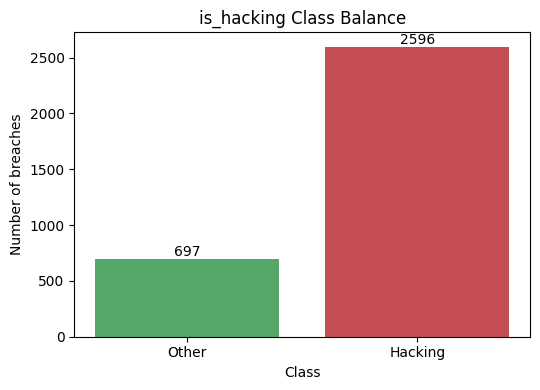

Saved figure -> /content/drive/MyDrive/HealthSec_FS/HIPAA/figures/class_distribution.png


In [ ]:
# Plot the is_hacking class balance and SAVE it into the figures/ folder.
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.bar([LABELS[k] for k in (0,1)], [int(dist.get(k,0)) for k in (0,1)],
       color=['#55A868', '#C44E52'])
ax.set_title('is_hacking Class Balance')
ax.set_xlabel('Class'); ax.set_ylabel('Number of breaches')
for i,k in enumerate((0,1)):
    ax.text(i, int(dist.get(k,0)), str(int(dist.get(k,0))), ha='center', va='bottom')
plt.tight_layout()
fig_path = os.path.join(PATHS['figures'], 'class_distribution.png')
plt.savefig(fig_path, dpi=150, bbox_inches='tight')
plt.show()
print("Saved figure ->", fig_path)

## Section 5 — Stratified Train/Test Split (80/20)
We assemble the final feature matrix (dropping text/identifier columns the model won't use),
then split **stratified on `is_hacking`** so the class balance is preserved in both sets.

## Section 3e — Export feature-engineered data as CSV (for the unified NB1_FINAL)
Saves the fully feature-engineered table (all engineered features **plus** the target),
**before** the split/impute/scale. `NB1_FINAL_dataprep` will read this CSV and apply the
common split, imputation, and scaling, so every dataset gets identical downstream treatment.

In [ ]:
# Build the feature-engineered export: engineered features + the target column.
# We drop only raw identifiers / free-text / intermediate columns (NOT the target here).
_EXPORT_DROP = ['entity_name', 'web_desc', 'submit_date', 'entity_type', 'breach_type',
                'location', 'business_assoc', 'state', 'region']
_fe_cols = [c for c in df.columns if c not in _EXPORT_DROP]      # keeps 'is_hacking' (target)
fe_export = df[_fe_cols].copy()

# Standardize the target column name to 'is_attack' so ALL datasets match downstream.
# (HIPAA's target is 'is_hacking'; we keep both: rename a copy to 'is_attack'.)
if 'is_hacking' in fe_export.columns and 'is_attack' not in fe_export.columns:
    fe_export = fe_export.rename(columns={'is_hacking': 'is_attack'})

_fe_csv = os.path.join(PATHS['processed'], 'feature_engineered.csv')
fe_export.to_csv(_fe_csv, index=False)
print(f'Saved feature-engineered CSV: {_fe_csv}')
print(f'  shape: {fe_export.shape}  (features + target)')
print(f'  target column: is_attack   positives: {int(fe_export["is_attack"].sum())}')
print('  -> feed this CSV to NB1_FINAL_dataprep (label_col="is_attack", benign_keyword="0").')

Saved feature-engineered CSV: /content/drive/MyDrive/HealthSec_FS/HIPAA/processed/feature_engineered.csv
  shape: (3293, 33)  (features + target)
  target column: is_attack   positives: 2596
  -> feed this CSV to NB1_FINAL_dataprep (label_col="is_attack", benign_keyword="0").


In [ ]:
# Columns that are NOT model features: raw identifiers, free text, intermediate columns,
# and the target itself. Size features (individuals, log_*, is_large_breach, ...) ARE kept --
# they are legitimate, non-leaky predictors for the hacking target.
DROP_COLS = ['entity_name', 'web_desc', 'submit_date', 'entity_type', 'breach_type',
             'location', 'business_assoc', 'state', 'region',
             'is_hacking']   # is_hacking is the TARGET (excluded from X)

# X = all engineered features; y = the target.
feature_cols = [c for c in df.columns if c not in DROP_COLS]
X = df[feature_cols].copy()
y = df['is_hacking'].copy()
print(f"Feature matrix: {X.shape[1]} features, {X.shape[0]} rows")

# Stratified 80/20 split. random_state fixed for reproducibility.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print(f"Train: {X_train.shape}   Test: {X_test.shape}")

Feature matrix: 32 features, 3293 rows
Train: (2634, 32)   Test: (659, 32)


## Section 6 — Train-Derived Aggregate Features (leakage-safe)
These features summarise how *frequent* a category is. Because frequency is computed across
rows, computing it on the full dataset would leak test information into training. So we learn
each frequency map from **training rows only**, then apply it to both train and test.

In [ ]:
# Helper: learn a frequency map from a TRAIN column, then apply to any split.
def add_train_frequency(train_series, apply_series):
    # Return frequency-encoded values; unseen categories in apply_series get 0.
    freq = train_series.value_counts(normalize=True)        # learned on TRAIN only
    return apply_series.map(freq).fillna(0.0)

# We need the original categorical columns aligned to the split indices to build these.
state_full  = df['state']  if 'state'  in df.columns else pd.Series(['NA']*len(df))
etype_full  = df['entity_type']
month_full  = df['submit_date'].dt.to_period('M').astype(str)

for split_name, idx, Xref in [('train', X_train.index, X_train), ('test', X_test.index, X_test)]:
    # state frequency (learned on train indices)
    Xref['state_freq'] = add_train_frequency(state_full.loc[X_train.index], state_full.loc[idx]).values
    # entity-type frequency
    Xref['entity_type_freq'] = add_train_frequency(etype_full.loc[X_train.index], etype_full.loc[idx]).values
    # monthly breach-volume frequency
    Xref['month_freq'] = add_train_frequency(month_full.loc[X_train.index], month_full.loc[idx]).values

print("Added 3 train-derived frequency features (state_freq, entity_type_freq, month_freq).")
print("New feature count:", X_train.shape[1])

Added 3 train-derived frequency features (state_freq, entity_type_freq, month_freq).
New feature count: 35


## Section 6b — Missing-Value Verification & Imputation (leakage-safe)
By construction the engineered feature matrix should already be free of missing values
(critical rows were dropped, and categorical gaps were absorbed during encoding). This cell
makes that **explicit and auditable**: it reports any residual NaN, fills anything unexpected
using values learned from the **training set only** (continuous → train median, binary/one-hot
→ 0), and then asserts the matrix is completely NaN-free before scaling and modelling.

Placed here (start of preprocessing) because this is the first point where the full feature
matrix exists, and doing the fill train-only keeps it leakage-safe.

In [ ]:
# 1) Report any residual missing values per column (across train and test).
na_train = X_train.isna().sum()
na_test  = X_test.isna().sum()
resid = pd.DataFrame({'train_NaN': na_train, 'test_NaN': na_test})
resid = resid[(resid['train_NaN'] > 0) | (resid['test_NaN'] > 0)]
if len(resid):
    print("Residual missing values found (these will be imputed):")
    print(resid)
else:
    print("No missing values in the feature matrix (as expected by construction).")

# 2) Defensive imputation. Fill values are learned from TRAIN only (no leakage):
#    binary/one-hot columns -> 0 ; continuous columns -> training median.
for col in X_train.columns:
    if X_train[col].isna().any() or X_test[col].isna().any():
        train_vals = set(pd.unique(X_train[col].dropna()))
        fill = 0 if train_vals.issubset({0, 1}) else X_train[col].median()
        X_train[col] = X_train[col].fillna(fill)
        X_test[col]  = X_test[col].fillna(fill)

# 3) Hard guarantee: no NaN may reach the scaler / models.
assert X_train.isna().sum().sum() == 0, "Unexpected NaN remains in X_train"
assert X_test.isna().sum().sum()  == 0, "Unexpected NaN remains in X_test"
print("Verified: feature matrix is NaN-free.")

No missing values in the feature matrix (as expected by construction).
Verified: feature matrix is NaN-free.


## Section 7 — Scaling (fit on training only)
Continuous features are standardised. The scaler is **fit on the training set only** and then
applied to the test set, so no test statistics leak into training. Binary flags and one-hot
columns are left untouched.

In [ ]:
# Identify continuous columns to scale (everything that isn't a 0/1 flag or one-hot column).
binary_like = [c for c in X_train.columns
               if set(pd.unique(X_train[c])).issubset({0, 1})]
continuous_cols = [c for c in X_train.columns if c not in binary_like]
print(f"Scaling {len(continuous_cols)} continuous columns; leaving {len(binary_like)} binary/one-hot columns as-is.")

# Fit the scaler on TRAIN continuous columns only, then transform both splits.
scaler = StandardScaler()
X_train[continuous_cols] = scaler.fit_transform(X_train[continuous_cols])
X_test[continuous_cols]  = scaler.transform(X_test[continuous_cols])

# Save the fitted scaler so the modelling notebooks reuse the exact same transform.
scaler_path = os.path.join(PATHS['models'], 'scaler.joblib')
joblib.dump({'scaler': scaler, 'continuous_cols': continuous_cols}, scaler_path)
print("Saved scaler ->", scaler_path)

Scaling 12 continuous columns; leaving 23 binary/one-hot columns as-is.
Saved scaler -> /content/drive/MyDrive/HealthSec_FS/HIPAA/models/scaler.joblib


## Section 8 — Save Processed Artifacts
Persist the train/test splits and metadata to Drive so Notebooks 2–4 can load them directly.

In [ ]:
# Save the splits as .parquet (compact, preserves dtypes). y saved alongside as a column.
train_out = X_train.copy(); train_out['is_hacking'] = y_train.values
test_out  = X_test.copy();  test_out['is_hacking']  = y_test.values

train_path = os.path.join(PATHS['processed'], 'train.parquet')
test_path  = os.path.join(PATHS['processed'], 'test.parquet')
train_out.to_parquet(train_path, index=False)
test_out.to_parquet(test_path, index=False)
print("Saved:", train_path)
print("Saved:", test_path)

# Save the feature list + basic metadata to results/ for traceability and the paper's methods section.
meta = {
    'n_features': int(X_train.shape[1]),
    'n_train': int(X_train.shape[0]),
    'n_test': int(X_test.shape[0]),
    'feature_names': list(X_train.columns),
    'continuous_cols': continuous_cols,
    'binary_cols': binary_like,
    'class_labels': LABELS,
    'class_distribution_full': {int(k): int(v) for k, v in dist.items()},
    'date_range': [str(df['submit_date'].min().date()), str(df['submit_date'].max().date())],
}
meta_path = os.path.join(PATHS['results'], 'notebook1_metadata.json')
with open(meta_path, 'w') as f:
    json.dump(meta, f, indent=2)
print("Saved:", meta_path)

Saved: /content/drive/MyDrive/HealthSec_FS/HIPAA/processed/train.parquet
Saved: /content/drive/MyDrive/HealthSec_FS/HIPAA/processed/test.parquet
Saved: /content/drive/MyDrive/HealthSec_FS/HIPAA/results/notebook1_metadata.json


In [ ]:
# Final summary of what Notebook 1 produced.
print("="*60)
print("NOTEBOOK 1 COMPLETE")
print("="*60)
print(f"Features engineered : {X_train.shape[1]}")
print(f"Train rows          : {X_train.shape[0]}")
print(f"Test rows           : {X_test.shape[0]}")
print(f"Classes             : {LABELS}")
print("\nSaved to your Drive under:", PROJECT_ROOT)
print("  processed/train.parquet, processed/test.parquet")
print("  models/scaler.joblib")
print("  results/notebook1_metadata.json")
print("  figures/class_distribution.png")

NOTEBOOK 1 COMPLETE
Features engineered : 35
Train rows          : 2634
Test rows           : 659
Classes             : {0: 'Other', 1: 'Hacking'}

Saved to your Drive under: /content/drive/MyDrive/HealthSec_FS/HIPAA
  processed/train.parquet, processed/test.parquet
  models/scaler.joblib
  results/notebook1_metadata.json
  figures/class_distribution.png


## Section 9 — Done · What Comes Next
NB0 has produced a clean, leakage-safe, ~40-feature dataset with a binary `is_hacking`
target, saved to your Drive.

**Reminder on SMOTE:** we deliberately did **not** balance the classes here. SMOTE (or class
weights — we'll compare both) will be applied **inside the cross-validation loop** in the
modelling notebooks, on training folds only. Saving the honest, unbalanced split keeps it
reusable and prevents the most common leakage mistake.

**Next:** NB1 — data preparation for all four datasets, which reads the exported `feature_engineered.csv`; NB2 then runs the 30 feature-selection methods.
